# VisionTrack — Analysis Notebook

## Experiment 01: Pre-trained YOLOv8n vs fine-tuned `best.pt`

**Date:** 2026-10-19. **Goal:** investigate how model choice and detection confidence affect line-crossing counts and reported processing speed in two Streamlit video streams, **Crosswalk** and **Mall**.

**Evidence:** four screenshots recorded after processing the videos. Source observations are preserved in `../reports/experiments/model_comparison.csv` and `../reports/experiments/screenshots/`.

> ⚠️ These are observed *LineZone counters*, not ground-truth person counts. Without manual verification of crossings, higher IN/OUT numbers **do not prove** greater accuracy. FPS and latency are values shown in the UI, not a separately controlled benchmark.

### Experimental setup

- Models: standard COCO-pretrained `yolov8n.pt` versus user fine-tuned `models/checkpoints/best.pt` (single class: `person`).
- Confidence thresholds: **0.50** and **0.35**.
- Input video sources: `data/raw_videos/crosswalk.mp4`, `data/raw_videos/mall.mp4`.
- Tracking: `supervision.ByteTrack`; counting: `supervision.LineZone`.
- Tracking and Counting toggles were enabled in the screenshots.
- Metrics recorded from final Streamlit display: IN, OUT, FPS, latency in milliseconds.
- Hardware, processing time, warm-up conditions, and repeated trials were **not independently measured**, so FPS comparisons are indicative only.

**Reproducibility notes:** run each pair from the beginning with a newly initialized tracker/LineZone. Keep videos, ROI line placement, resizing and application configuration identical. Repeat runs and measure FPS independently for rigorous benchmarking.

In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
CSV_PATH = PROJECT_ROOT / 'reports' / 'experiments' / 'model_comparison.csv'
df = pd.read_csv(CSV_PATH)
df['model_label'] = df['model'].str.replace('.pt', '', regex=False) + ' / ' + df['confidence'].map(lambda x: f'{x:.2f}')
display(df.drop(columns=['screenshot']))

,model,confidence,crosswalk_in,crosswalk_out,crosswalk_fps,crosswalk_latency_ms,mall_in,mall_out,mall_fps,mall_latency_ms,crosswalk_total_crossings,mall_total_crossings,model_label
0,best.pt,0.50,0,4,49.6,20.2,7,7,50.0,20.0,4,14,best / 0.50
1,best.pt,0.35,0,9,48.4,20.7,7,10,47.6,21.0,9,17,best / 0.35
2,yolov8n.pt,0.50,3,16,45.0,22.2,9,12,44.1,22.7,19,21,yolov8n / 0.50
3,yolov8n.pt,0.35,5,21,47.8,20.9,8,12,46.9,21.3,26,20,yolov8n / 0.35


### Recorded results

| Model | Confidence | Crosswalk IN | Crosswalk OUT | Mall IN | Mall OUT | Crosswalk FPS | Mall FPS | Crosswalk latency (ms) | Mall latency (ms) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| best.pt | 0.50 | 0 | 4 | 7 | 7 | 49.6 | 50.0 | 20.2 | 20.0 |
| best.pt | 0.35 | 0 | 9 | 7 | 10 | 48.4 | 47.6 | 20.7 | 21.0 |
| yolov8n.pt | 0.50 | 3 | 16 | 9 | 12 | 45.0 | 44.1 | 22.2 | 22.7 |
| yolov8n.pt | 0.35 | 5 | 21 | 8 | 12 | 47.8 | 46.9 | 20.9 | 21.3 |

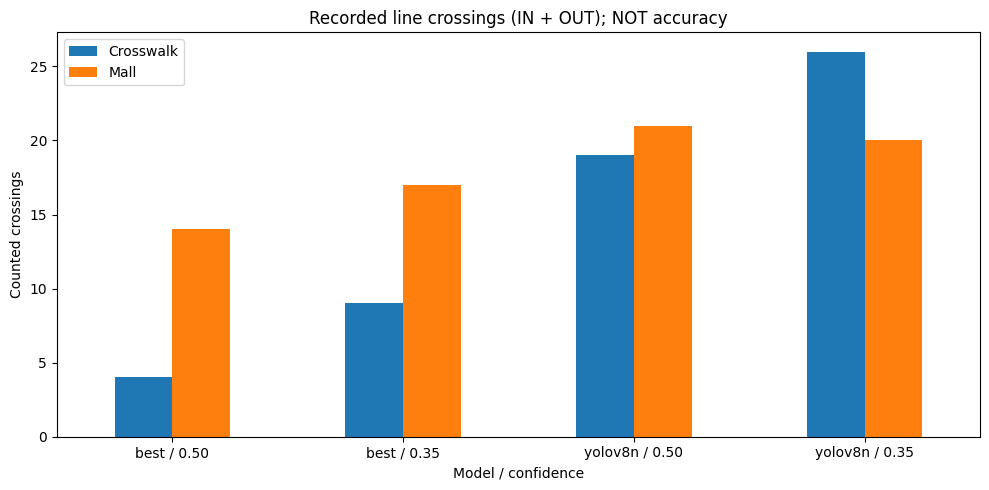

In [8]:
ax = df.plot(x='model_label', y=['crosswalk_total_crossings', 'mall_total_crossings'], kind='bar', figsize=(10, 5))
ax.set_title('Recorded line crossings (IN + OUT); NOT accuracy')
ax.set_xlabel('Model / confidence')
ax.set_ylabel('Counted crossings')
ax.legend(['Crosswalk', 'Mall'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

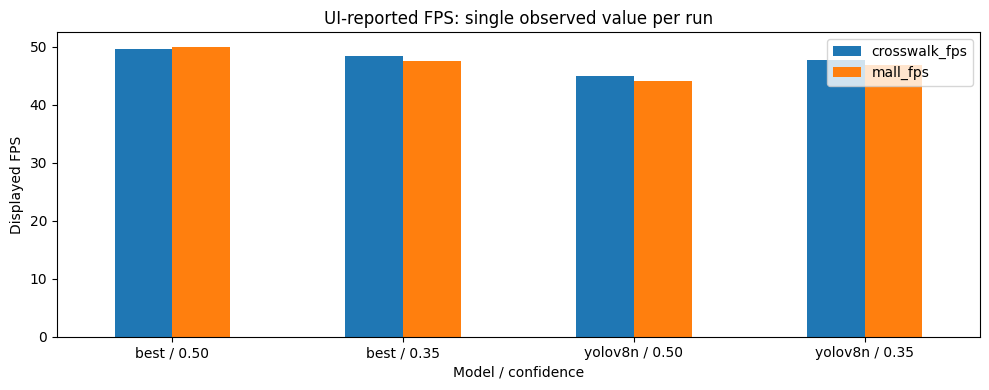

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
df.plot(x='model_label', y=['crosswalk_fps', 'mall_fps'], kind='bar', ax=ax)
ax.set_title('UI-reported FPS: single observed value per run')
ax.set_xlabel('Model / confidence')
ax.set_ylabel('Displayed FPS')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

1. Standard `yolov8n.pt` produced more recorded crossings than `best.pt` at both matching confidence thresholds. At **0.35**, Crosswalk recorded **26** vs **9**, while Mall recorded **20** vs **17**.
2. Lowering confidence from **0.50** to **0.35** increased recorded crossings on Crosswalk for both models; on Mall the totals changed from **14 to 17** for fine-tuned weights and **21 to 20** for the standard model.
3. The screenshots suggest the pretrained model identifies more distant people, but a visual impression is **not a formal detection metric**.
4. The pretrained model is a reasonable **provisional** application choice. Final selection requires counting against manually annotated crossings plus precision/recall/F1 on a labeled dataset.
5. UI-reported FPS ranged from **44.1 to 50.0** across these runs, but a single screenshot value cannot establish reliable throughput or speedup.

### Screenshot evidence

These files are copies of screenshots supplied during development; they document the final UI state of each experimental run.

**Fine-tuned best.pt, 0.50**

![](../reports/experiments/screenshots/Screenshot%202026-10-19%20at%2016.38.26.png)

**Fine-tuned best.pt, 0.35**

![](../reports/experiments/screenshots/Screenshot%202026-10-19%20at%2016.42.25.png)

**Pre-trained yolov8n.pt, 0.50**

![](../reports/experiments/screenshots/Screenshot%202026-10-19%20at%2016.46.00.png)

**Pre-trained yolov8n.pt, 0.35**

![](../reports/experiments/screenshots/Screenshot%202026-10-19%20at%2016.48.07.png)

### Validation status after model evaluation

- **Completed:** three-model detection evaluation on 96 validation images (249 labeled person instances), and model benchmark with two video sources. See Experiment 02 below.
- **Completed:** INT8 static quantization, ONNX Runtime loading, and comparison of size/quality/speed. See Experiment 03.
- **Pending:** ground-truth manual review of individual IN/OUT crossing events for fixed clips. Observed screenshot counters are **not counting accuracy**.
- **Pending:** independent test-set assessment (the available `val` split was also used during development); current metrics must be labeled validation metrics.
- **Pending:** repeated end-to-end app benchmarks, if required for stronger performance claims.

These limits do not invalidate the documented experiments; they constrain the claims that can be made.

---
## Experiment 02 — Training setup and detection evaluation

### Fine-tuning configuration (from `models/train_yolo.py`)

- Base checkpoint: `yolov8n.pt` (COCO pretrained); target class in custom checkpoint: `person` (class 0).
- Dataset: `data/person_dataset/data.yaml`; **376 training** and **96 validation images** (validation contains **249 labeled person instances**).
- `epochs=30`, `imgsz=768`, `batch=8`, optimizer **AdamW**, `lr0=0.0005`, `lrf=0.01`, `cos_lr=True`.
- `weight_decay=0.0005`, `momentum=0.937`, `patience=10`.
- Augmentation: `fliplr=0.5`, `translate=0.1`, `scale=0.4`, `mosaic=1.0`, `mixup=0.1`.
- Device selection in training script: CUDA, else Apple MPS, else CPU. The **reported evaluation** was on **Apple M4 CPU**, not MPS.
- Training run path configured as `runs/visiontrack_person_v4`. Do not infer the number of actually completed epochs or best epoch without checking logs.

**Evaluation protocol:** `models/evaluate_model.py`, image size **640**, confidence threshold **0.35**, evaluator IoU setting **0.50**, validation split (`val`) with Ultralytics 8.4.182. Reported precision/recall are Ultralytics aggregate validation statistics (`results.box.mp` and `mr`), and `F1 = 2PR/(P+R)` is computed from them. These are **validation metrics**, not performance on a completely independent test set.

### Final model evaluation results (measured, 2026-10-19)

Validation: **96 labeled images, 249 person instances**; confidence **0.35**, IoU **0.50**, CPU (Apple M4). FPS per stream is from the two-video inference benchmark, **not Streamlit display FPS**.

| Model | Precision | Recall | F1-score | mAP50 | mAP50–95 | FPS/stream | Latency (ms) |
|:--|--:|--:|--:|--:|--:|--:|--:|
| Pre-trained YOLOv8n | 0.7538 | 0.7470 | 0.7504 | 0.7311 | 0.5308 | 22.02 | 19.63 |
| **Fine-tuned best.pt** | 0.8578 | **0.7590** | **0.8054** | **0.7629** | **0.5865** | **23.67** | **18.08** |
| INT8 ONNX | **0.8729** | 0.7349 | 0.7980 | 0.7459 | 0.5575 | 16.35 | 27.32 |

**Interpretation:** Fine-tuning improved validation F1 and mAP50; the INT8 model reduced ONNX file size from **11.67 MB to 3.22 MB** (~72.4%), but was slower on this CPU benchmark. These are validation-set measurements, not proof of improved counting accuracy on the Crosswalk/Mall videos. Detailed reproducible results are also stored in `reports/performance_metrics.json`.


In [10]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
report_file = root / "reports" / "performance_metrics.json"

# Recorded actual output from the 2026-10-19 evaluation, used as an
# auditable fallback when the separate report is unavailable.
recorded = {
    "pretrained_yolov8n": {"precision": 0.7538, "recall": 0.7470, "f1_score": 0.7504, "map50": 0.7311, "map50_95": 0.5308, "fps": 22.02, "latency_ms": 19.63},
    "fine_tuned": {"precision": 0.8578, "recall": 0.7590, "f1_score": 0.8054, "map50": 0.7629, "map50_95": 0.5865, "fps": 23.67, "latency_ms": 18.08},
    "quantized_onnx": {"precision": 0.8729, "recall": 0.7349, "f1_score": 0.7980, "map50": 0.7459, "map50_95": 0.5575, "fps": 16.35, "latency_ms": 27.32},
}

if report_file.is_file():
    with report_file.open(encoding="utf-8") as f:
        raw_report = json.load(f)
    model_report = raw_report.get("models", {})
    if model_report and all(model_report.get(k, {}).get("status") == "success" for k in recorded):
        for k in recorded:
            d = model_report[k]["detection"]
            p = model_report[k]["performance"]
            recorded[k] = {
                "precision": d["precision"], "recall": d["recall"],
                "f1_score": d["f1_score"], "map50": d["map50"],
                "map50_95": d["map50_95"],
                "fps": p["average_fps_per_stream"],
                "latency_ms": p["average_latency_ms"],
            }
        print("Source: reports/performance_metrics.json")
    else:
        print("Incomplete report; using recorded 2026-10-19 experiment values")
else:
    print("Report not found; using recorded 2026-10-19 experiment values")

metrics_df = pd.DataFrame.from_dict(recorded, orient="index")
metrics_df.index.name = "model"
display(metrics_df.round(4))

Source: reports/performance_metrics.json


,precision,recall,f1_score,map50,map50_95,fps,latency_ms
model,,,,,,,
pretrained_yolov8n,0.7538,0.7470,0.7504,0.7311,0.5308,22.02,19.63
fine_tuned,0.8578,0.7590,0.8054,0.7629,0.5865,23.67,18.08
quantized_onnx,0.8729,0.7349,0.7980,0.7459,0.5575,16.35,27.32


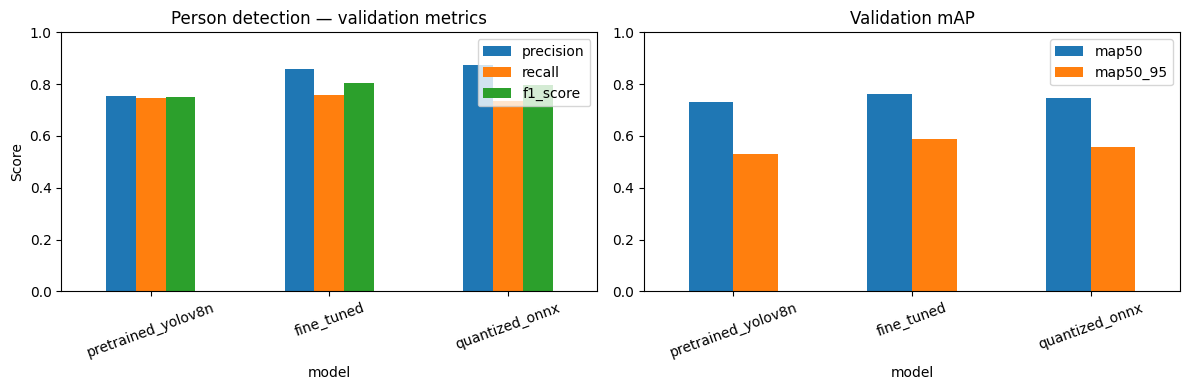

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_df[["precision", "recall", "f1_score"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Person detection — validation metrics")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=20)
metrics_df[["map50", "map50_95"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("Validation mAP")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**Evaluation finding:** Fine-tuning improved validation F1 **0.7504 → 0.8054** (+0.0550 absolute) and mAP50 **0.7311 → 0.7629**. This **does not contradict** the earlier observation that the standard model counted more Crosswalk/Mall line crossings. Those videos may differ from the training/validation images, and the crossing totals were not compared against manual ground truth.

The INT8 ONNX model attained validation F1 **0.7980** (0.0074 below the fine-tuned PyTorch checkpoint) and recall **0.7349**. These results are from the same validation split, not an independent test.

---
## Experiment 03 — ONNX export, static INT8 quantization and speed

- Exported: `models/checkpoints/best.pt` → `best.onnx` (opset **17**, fixed 640×640 input).
- Static calibration: **50** dataset images; ONNX Runtime **1.19.2**; QDQ; MinMax; quantization includes `Conv` and `MatMul` operations.
- Verified both ONNX variants with ONNX Runtime **CPUExecutionProvider**; sample output shape `(1, 5, 8400)` and finite values.
- Original ONNX size: **11.67 MB**; INT8 output: **3.22 MB** (approximately **72.4%** smaller).
- Hardware for benchmarks: **Apple M4, CPU**. Quantization **reduced storage size but did not improve throughput** in this environment.

**Benchmark methodology:** 60 frames of Crosswalk and 60 of Mall, alternated through a shared model on CPU. Per-stream FPS is `frames_processed_for_stream / total_elapsed_seconds`. This is **not** the full Streamlit UI render rate or parallel hardware inference. Mean per-frame inference-call latency is measured separately from total elapsed time (including loop, reads, etc.).

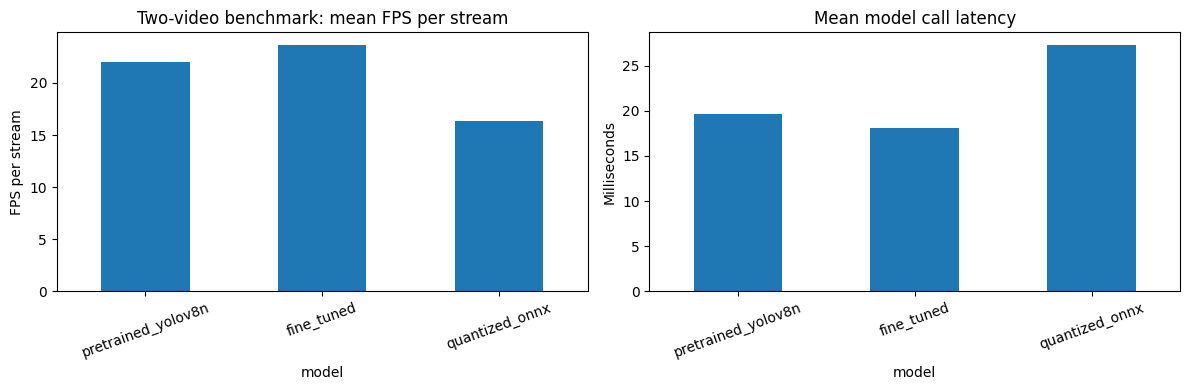

ONNX model size: 11.67 → 3.22 MB; reduction 72.4%
Fine-tuned vs quantized FPS: 23.67 vs 16.35


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_df["fps"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Two-video benchmark: mean FPS per stream")
axes[0].set_ylabel("FPS per stream")
axes[0].tick_params(axis="x", rotation=20)
metrics_df["latency_ms"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Mean model call latency")
axes[1].set_ylabel("Milliseconds")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

original_mb, quantized_mb = 11.67, 3.22
size_reduction_pct = 100 * (original_mb - quantized_mb) / original_mb
print(f"ONNX model size: {original_mb:.2f} → {quantized_mb:.2f} MB; reduction {size_reduction_pct:.1f}%")
print(f"Fine-tuned vs quantized FPS: {metrics_df.loc['fine_tuned', 'fps']:.2f} vs {metrics_df.loc['quantized_onnx', 'fps']:.2f}")

---
## Experiment 04 — Application evidence and counting limitations

- The Streamlit application processes two video sources named Crosswalk and Mall and displays detection boxes, tracked IDs, line-crossing counts, latency and processing FPS.
- Final audit artifacts are expected at `reports/demo_results/roi_counting_example.png` and `reports/demo_results/multi_stream_demo.mp4`. Generation and visual inspection of the MP4 was reported complete, but these outputs must be included in the final submission.
- `LineZone` counts crossings of a **line**, not necessarily occupancy within a polygonal ROI. In/Out orientation depends on line direction.
- Screenshot observations alone cannot quantify counting accuracy. **No manually annotated crossing ground truth is recorded in this notebook**; do not claim validated counting accuracy based only on those values.
- A useful remaining test is to manually annotate crossing events over a fixed period for each source and compare correct, missed, and extra IN/OUT events.

### Conclusions for audit

1. Standard YOLOv8n was selected provisionally for application footage based on broader *observed* detections; validation scores favor the fine-tuned checkpoint. This tradeoff is explicitly documented rather than treated as a contradiction.
2. Fine-tuning improved validation F1 and mAP50 on the given person dataset.
3. INT8 quantization reduced the ONNX model file size substantially while slightly lowering validation F1 and reducing observed FPS on this Apple M4 CPU test.
4. Detection validation, exploratory crossing-count comparisons and the FPS benchmark are **different kinds of evidence** and must not be conflated.
5. Full submission still depends on verifying playback of artifacts, correct app operation/error handling, and ideally manual counting validation and an independent test set.